# 06 Advanced Models: Gradient Boosting

**IDX Exchange Data Science Internship, Week 7 deliverable** (the task document names it `05_advanced_models.ipynb`; this project's notebooks are numbered one step ahead)

**Goal.** Train a gradient-boosted tree model (LightGBM), tune its depth, learning rate and number of trees lightly on the validation month, and report its test-month results next to the earlier models.

**How gradient boosting differs from a random forest.** A random forest trains many deep trees independently and averages them. Gradient boosting trains small trees one after another: each new tree is fit to the errors the current model still makes, and its prediction is added in, scaled down by the *learning rate*. A smaller learning rate takes smaller steps and usually needs more trees. The *depth* limits how many questions each tree may ask.

**Setup, carried over from Week 6.**
- Inputs: the full Week 6 set, including the nearby-sales price per square foot (100 nearest training sales).
- Training window: **24 months**, the window chosen for the forest in Week 6.
- Settings split: train on March 2024 to February 2026, choose settings on the **validation month**, March 2026. Final: train on April 2024 to March 2026, score once on the **test month**, April 2026.
- Settings are chosen with the one-standard-error rule (the simplest setting statistically tied with the best).
- Every model predicts log price. MdAPE (median percentage error) is the headline measure; R², MAPE and MAE are also reported.

**Also this week.** Week 6 left one question open: did the 24-month window help because of the new inputs, or would the forest have gained from more data anyway? Section 6 answers it.

**Contents**
1. Load the data and prepare the inputs
2. Tuning LightGBM on the validation month
3. The test month: all models compared
4. Is LightGBM's gain real?
5. Stability over 2025
6. Open question from Week 6: why the 24-month window helps
7. Where LightGBM helps
8. What LightGBM relies on
9. Saved results
10. Summary and next steps

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import lightgbm as lgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

ROOT = next(p for p in [Path('..'), Path('.')] if (p / 'src' / 'preprocessing.py').exists()).resolve()
sys.path.insert(0, str(ROOT))
import src.preprocessing as prep
import src.modeling as mdl
import src.features as feat

SEED = prep.set_global_seed()
print('Random seed:', SEED, '| LightGBM', lgb.__version__)

SPLIT = json.loads((ROOT / 'config' / 'split_config.json').read_text())
W6 = json.loads((ROOT / 'config' / 'model_config_week6.json').read_text())
RESULTS_DIR = ROOT / 'results'
FIG_DIR = ROOT / 'reports' / 'figures'
TEST_MONTH = SPLIT['final']['test_month']
VALIDATION_MONTH = SPLIT['tuning']['validation_month']
NEARBY_K = int(W6['nearby_k'])
N_MONTHS = int(W6['window_check_one_se_choice']['Random forest'])     # 24
N_MONTHS_COMPARE = int(SPLIT['n_train_months'])                     # 12, for month-by-month checks
FULL = feat.WITH_NEARBY
RF_SETTINGS = {k: v for k, v in W6['chosen_settings']['+ nearby sales price per sq ft | Random forest'].items()}

COLORS = {'Linear regression': '#2a78d6', 'Random forest': '#1baf7a', 'LightGBM': '#4a3aa7', 'Baseline': '#a3a29d'}
LIGHT_GRAY = '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c9c8c3', 'axes.linewidth': 0.8, 'axes.grid': True,
    'grid.color': LIGHT_GRAY, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e', 'font.size': 9.5,
})
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')


def save_fig(name):
    plt.savefig(FIG_DIR / f'{name}.png', dpi=130, bbox_inches='tight')


def money(x, _=None):
    return f'${x / 1e6:.1f}M' if abs(x) >= 1e6 else f'${x / 1e3:.0f}K'


def pct_axis(ax, decimals=1):
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.{decimals}f}%'))


def show(df):
    out = df.copy()
    formats = {'R2': '{:.3f}', 'MAPE': '{:.2f}%', 'MdAPE': '{:.2f}%', 'within 10%': '{:.2f}%', 'MAE': '${:,.0f}'}
    for c, f in formats.items():
        if c in out:
            out[c] = out[c].map(lambda v: '' if pd.isna(v) else f.format(v))
    return out


def lightgbm(learning_rate, max_depth, n_estimators):
    # Each tree may have up to 2^depth - 1 leaves; rows and inputs are subsampled (80%) for each tree
    return lgb.LGBMRegressor(learning_rate=learning_rate, max_depth=max_depth, num_leaves=2 ** max_depth - 1,
                             n_estimators=n_estimators, min_child_samples=20, subsample=0.8, subsample_freq=1,
                             colsample_bytree=0.8, random_state=SEED, deterministic=True, force_row_wise=True,
                             n_jobs=8, verbose=-1)


print(f'Training window {N_MONTHS} months; nearby sales k = {NEARBY_K}; random forest settings {RF_SETTINGS}')

Random seed: 42 | LightGBM 4.7.0
Training window 24 months; nearby sales k = 100; random forest settings {'n_estimators': 300, 'max_features': 0.2, 'min_samples_leaf': 2}


## 1. Load the data and prepare the inputs

The inputs are prepared once per split with `mdl.prepare_matrices`: the preprocessor (including the nearby-sales input) is fit on the training rows and applied to the evaluation rows. A model fit on these matrices gives exactly the same predictions as the full pipeline used in earlier weeks (this was checked), but many settings can then reuse one preparation.

In [2]:
data = feat.add_all_features(prep.load_clean(ROOT / 'data' / 'processed' / 'sfr_clean.csv'))
train_tune, val_tune, _ = prep.make_split(data, VALIDATION_MONTH, N_MONTHS)
train_final, test_final, _ = prep.make_split(data, TEST_MONTH, N_MONTHS)

start = time.time()
_, X_tune, X_val, ly_tune = mdl.prepare_matrices(FULL, train_tune, val_tune, nearby_k=NEARBY_K)
pre_final, X_final, X_test, ly_final = mdl.prepare_matrices(FULL, train_final, test_final, nearby_k=NEARBY_K)
y_val, y_test = val_tune[prep.TARGET].to_numpy(), test_final[prep.TARGET].to_numpy()
print(f'Prepared in {time.time() - start:.0f} s')
print(f'Settings split: {train_tune.CloseMonth.min()} to {train_tune.CloseMonth.max()} ({len(train_tune):,} sales) -> '
      f'{VALIDATION_MONTH} ({len(val_tune):,})')
print(f'Final split:    {train_final.CloseMonth.min()} to {train_final.CloseMonth.max()} ({len(train_final):,} sales) -> '
      f'{TEST_MONTH} ({len(test_final):,})')
print(f'{X_final.shape[1]} numeric columns from {len(FULL)} inputs')

Prepared in 80 s
Settings split: 2024-03 to 2026-02 (262,847 sales) -> 2026-03 (11,345)
Final split:    2024-04 to 2026-03 (262,805 sales) -> 2026-04 (12,248)
83 numeric columns from 24 inputs


## 2. Tuning LightGBM on the validation month

Three settings are tuned, as the task asks:
- **Learning rate:** 0.03, 0.05 or 0.1.
- **Depth:** at most 5, 6, 7 or 8 questions per tree (so at most 31, 63, 127 or 255 leaves).
- **Number of trees:** 250 to 3,000. A boosted model can be read off after any number of trees, so each depth and learning rate is trained once with 3,000 trees and scored at every count below that.

Other settings are fixed at common defaults: each tree sees a random 80% of the training homes and 80% of the input columns, and a leaf needs at least 20 homes. The one-standard-error rule then picks the setting with the fewest total leaves (trees × leaves per tree) among those statistically tied with the best.

In [3]:
RATES = [0.03, 0.05, 0.1]
DEPTHS = [5, 6, 7, 8]
TREE_COUNTS = [250, 500, 1000, 1500, 2000, 3000]

val_preds, complexity = {}, {}
start = time.time()
for rate in RATES:
    for depth in DEPTHS:
        model = lightgbm(rate, depth, max(TREE_COUNTS)).fit(X_tune, ly_tune)
        for n in TREE_COUNTS:
            val_preds[(rate, depth, n)] = np.exp(model.predict(X_val, num_iteration=n))
            complexity[(rate, depth, n)] = n * (2 ** depth - 1)
print(f'{len(RATES) * len(DEPTHS)} models, {len(val_preds)} settings scored in {time.time() - start:.0f} s')

GB_KEY, gb_table = mdl.one_se_select(y_val, val_preds, complexity)
GB_SETTINGS = {'learning_rate': GB_KEY[0], 'max_depth': GB_KEY[1], 'n_estimators': GB_KEY[2]}
best_key = gb_table['MdAPE'].idxmin()
print('Lowest validation MdAPE:', dict(zip(['learning_rate', 'max_depth', 'n_estimators'], best_key)),
      f"{gb_table.loc[[best_key], 'MdAPE'].item():.3f}%")
print('One-SE choice:          ', GB_SETTINGS, f"{gb_table.loc[[GB_KEY], 'MdAPE'].item():.3f}%")

12 models, 72 settings scored in 115 s


Lowest validation MdAPE: {'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 3000} 6.963%
One-SE choice:           {'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 3000} 6.963%


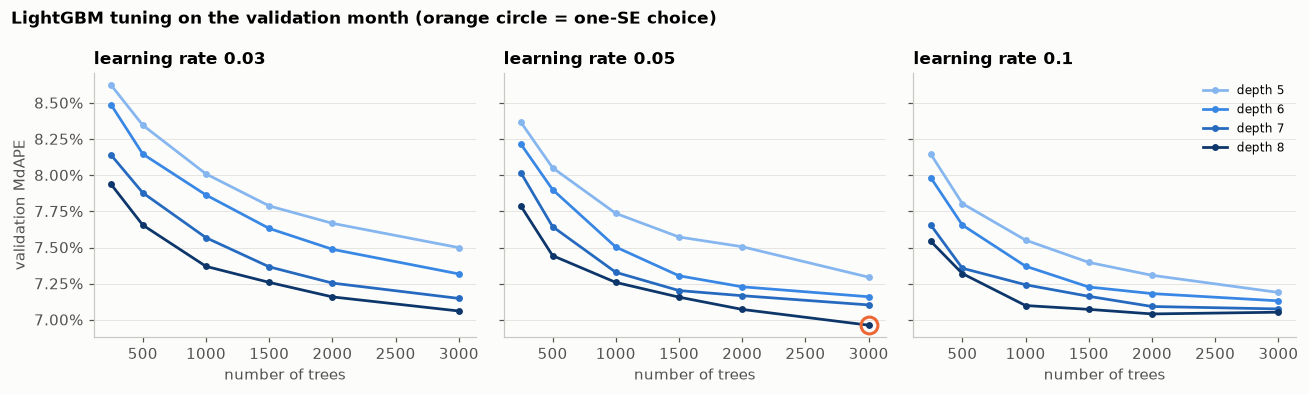

In [4]:
fig, axes = plt.subplots(1, len(RATES), figsize=(12, 3.6), sharey=True)
depth_colors = dict(zip(DEPTHS, ['#86b6ef', '#3987e5', '#256abf', '#0d366b']))
for ax, rate in zip(axes, RATES):
    for depth in DEPTHS:
        v = [gb_table.loc[[(rate, depth, n)], 'MdAPE'].item() for n in TREE_COUNTS]
        ax.plot(TREE_COUNTS, v, color=depth_colors[depth], lw=1.8, marker='o', ms=3.5, label=f'depth {depth}')
    if rate == GB_KEY[0]:
        ax.plot(GB_KEY[2], gb_table.loc[[GB_KEY], 'MdAPE'].item(), marker='o', ms=11, mfc='none', mec='#eb6834', mew=2)
    ax.set_title(f'learning rate {rate}')
    ax.set_xlabel('number of trees')
    ax.grid(axis='x', visible=False)
pct_axis(axes[0], 2)
axes[0].set_ylabel('validation MdAPE')
axes[-1].legend(frameon=False, fontsize=8)
fig.suptitle('LightGBM tuning on the validation month (orange circle = one-SE choice)', x=0.01, ha='left',
             fontsize=11, fontweight='bold')
plt.tight_layout()
save_fig('06_gb_tuning')
plt.show()

For comparison, the Week 6 random forest and linear regression are scored on the same validation month with the same inputs and window.

In [5]:
rf_val = np.exp(RandomForestRegressor(**RF_SETTINGS, n_jobs=-1, random_state=SEED).fit(X_tune, ly_tune).predict(X_val))
lr_val = np.exp(LinearRegression().fit(X_tune, ly_tune).predict(X_val))
validation = pd.DataFrame({
    'Linear regression': prep.regression_metrics(y_val, lr_val),
    'Random forest': prep.regression_metrics(y_val, rf_val),
    'LightGBM': prep.regression_metrics(y_val, val_preds[GB_KEY]),
}).T
show(validation)

,R2,MAPE,MdAPE,MAE
Linear regression,0.870,12.95%,9.49%,"$167,852"
Random forest,0.904,10.62%,7.35%,"$142,623"
LightGBM,0.926,10.08%,6.96%,"$131,272"


## 3. The test month: all models compared

The chosen LightGBM is trained on April 2024 to March 2026 and scored once on April 2026, next to the Week 6 random forest and linear regression with the same inputs and window. The Week 4 baseline and the Week 5 random forest (original inputs, 12 months) are read from their saved results.

In [6]:
models = {
    'Linear regression': LinearRegression(),
    'Random forest': RandomForestRegressor(**RF_SETTINGS, n_jobs=-1, random_state=SEED),
    'LightGBM': lightgbm(**GB_SETTINGS),
}
test_preds, fit_seconds = {}, {}
for name, model in models.items():
    start = time.time()
    model.fit(X_final, ly_final)
    fit_seconds[name] = time.time() - start
    test_preds[name] = np.exp(model.predict(X_test))
final_gb = models['LightGBM']

rows = []
w4 = pd.read_csv(RESULTS_DIR / '03_baseline_metrics.csv').query('eval_month == @TEST_MONTH').iloc[0]
w5 = pd.read_csv(RESULTS_DIR / '04_model_comparison.csv').query('eval_month == @TEST_MONTH and model == "Random forest"').iloc[0]
rows.append({'model': 'Week 4 baseline: linear regression, original inputs, 12 months', **{k: w4[k] for k in ['R2', 'MAPE', 'MdAPE', 'MAE']}})
rows.append({'model': 'Week 5: random forest, original inputs, 12 months', **{k: w5[k] for k in ['R2', 'MAPE', 'MdAPE', 'MAE']}})
for name, p in test_preds.items():
    rows.append({'model': f'{name}, new inputs, {N_MONTHS} months', **prep.regression_metrics(y_test, p),
                 'within 10%': 100 * np.mean(np.abs(p - y_test) / y_test <= 0.10)})
comparison = pd.DataFrame(rows).set_index('model')
show(comparison)

,R2,MAPE,MdAPE,MAE,within 10%
model,,,,,
"Week 4 baseline: linear regression, original inputs, 12 months",0.820,15.17%,11.38%,"$207,051",
"Week 5: random forest, original inputs, 12 months",0.885,11.42%,7.76%,"$159,355",
"Linear regression, new inputs, 24 months",0.867,13.10%,9.46%,"$175,061",52.02%
"Random forest, new inputs, 24 months",0.900,10.81%,7.40%,"$148,862",61.41%
"LightGBM, new inputs, 24 months",0.920,10.12%,7.00%,"$136,276",64.20%


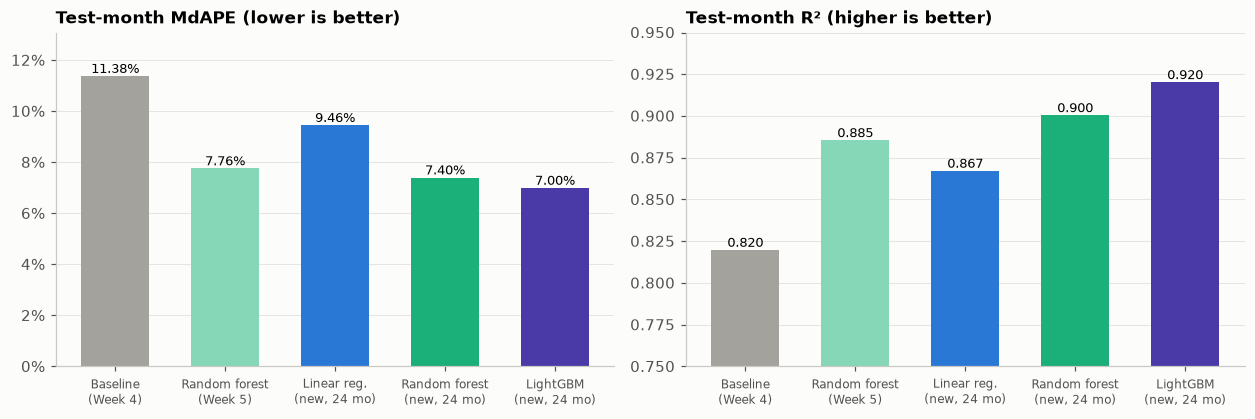

Training time on the final split: {'Linear regression': '0.5 s', 'Random forest': '10.9 s', 'LightGBM': '16.0 s'}


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
labels = ['Baseline\n(Week 4)', 'Random forest\n(Week 5)', 'Linear reg.\n(new, 24 mo)', 'Random forest\n(new, 24 mo)', 'LightGBM\n(new, 24 mo)']
colors = [COLORS['Baseline'], '#86d6b8', COLORS['Linear regression'], COLORS['Random forest'], COLORS['LightGBM']]
for ax, col, fmt, title in [(axes[0], 'MdAPE', '{:.2f}%', 'Test-month MdAPE (lower is better)'),
                            (axes[1], 'R2', '{:.3f}', 'Test-month R² (higher is better)')]:
    v = comparison[col].to_numpy()
    ax.bar(range(len(v)), v, color=colors, width=0.62)
    for i, val in enumerate(v):
        ax.text(i, val, fmt.format(val), ha='center', va='bottom', fontsize=8.5)
    ax.set_xticks(range(len(v)), labels, fontsize=8)
    ax.set_title(title)
    ax.grid(axis='x', visible=False)
axes[0].set_ylim(0, comparison['MdAPE'].max() * 1.15)
pct_axis(axes[0], 0)
axes[1].set_ylim(0.75, 0.95)
plt.tight_layout()
save_fig('06_test_comparison')
plt.show()
print('Training time on the final split:', {k: f'{v:.1f} s' for k, v in fit_seconds.items()})

## 4. Is LightGBM's gain real?

As in earlier weeks, the test homes are resampled with replacement 2,000 times and the MdAPE difference between two models is recomputed on each resample, with both scored on the same homes. The middle 95% of the differences gives a range for the true difference.

In [8]:
pairs = [('Random forest', 'LightGBM'), ('Linear regression', 'LightGBM')]
boot = pd.DataFrame([{'comparison': f'{a} minus {b}', **mdl.bootstrap_mdape_difference(y_test, test_preds[a], test_preds[b])}
                     for a, b in pairs]).set_index('comparison')
boot.columns = ['MdAPE difference (points)', '95% range low', '95% range high']
boot.round(2)

,MdAPE difference (points),95% range low,95% range high
comparison,,,
Random forest minus LightGBM,0.41,0.27,0.58
Linear regression minus LightGBM,2.46,2.27,2.67


## 5. Stability over 2025

The month-by-month check needs the training window to fit inside the data, which starts in January 2024. A 24-month window can only be trained for months from January 2026 on, so this check uses the **12-month window** (as in Week 6): for each month of 2025 and for the test month, the inputs are prepared on the 12 months before it, and the random forest and LightGBM are trained with the settings chosen above.

13 months in 417 s


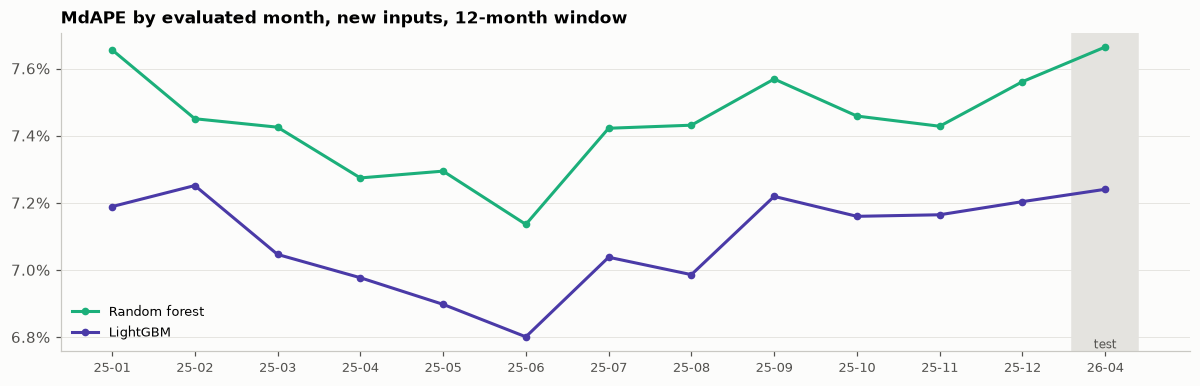

LightGBM better in 13 of 13 months; gain from 0.20 to 0.47 points (mean 0.35)


model,Random forest,LightGBM
eval_month,,
2025-01,7.66,7.19
2025-02,7.45,7.25
2025-03,7.43,7.05
2025-04,7.27,6.98
2025-05,7.30,6.90
2025-06,7.14,6.80
2025-07,7.42,7.04
2025-08,7.43,6.99
2025-09,7.57,7.22


In [9]:
STABILITY_MONTHS = [f'2025-{m:02d}' for m in range(1, 13)] + [TEST_MONTH]
stab_rows = []
start = time.time()
for month in STABILITY_MONTHS:
    tr, ev, _ = prep.make_split(data, month, N_MONTHS_COMPARE)
    _, Xtr, Xev, ly = mdl.prepare_matrices(FULL, tr, ev, nearby_k=NEARBY_K)
    y = ev[prep.TARGET].to_numpy()
    for name, model in [('Random forest', RandomForestRegressor(**RF_SETTINGS, n_jobs=-1, random_state=SEED)),
                        ('LightGBM', lightgbm(**GB_SETTINGS))]:
        p = np.exp(model.fit(Xtr, ly).predict(Xev))
        stab_rows.append({'model': name, 'eval_month': month, **prep.regression_metrics(y, p),
                          'median_signed_error': 100 * np.median((p - y) / y)})
stability = pd.DataFrame(stab_rows)
print(f'{len(STABILITY_MONTHS)} months in {time.time() - start:.0f} s')

fig, ax = plt.subplots(figsize=(11, 3.6))
for name in ['Random forest', 'LightGBM']:
    s = stability[stability['model'] == name]
    ax.plot(s['eval_month'], s['MdAPE'], color=COLORS[name], lw=2, marker='o', ms=4, label=name)
ax.axvspan(len(STABILITY_MONTHS) - 1.4, len(STABILITY_MONTHS) - 0.6, color=LIGHT_GRAY, zorder=0)
ax.set_xticks(range(len(STABILITY_MONTHS)), [m[2:] for m in STABILITY_MONTHS], fontsize=8.5)
ax.text(len(STABILITY_MONTHS) - 1, ax.get_ylim()[0], 'test', ha='center', va='bottom', fontsize=8, color='#52514e')
pct_axis(ax, 1)
ax.set_title('MdAPE by evaluated month, new inputs, 12-month window')
ax.legend(frameon=False, fontsize=8.5)
ax.grid(axis='x', visible=False)
plt.tight_layout()
save_fig('06_stability')
plt.show()

gap = (stability[stability.model == 'Random forest'].set_index('eval_month')['MdAPE']
       - stability[stability.model == 'LightGBM'].set_index('eval_month')['MdAPE'])
print(f'LightGBM better in {(gap > 0).sum()} of {len(gap)} months; gain from {gap.min():.2f} to {gap.max():.2f} points '
      f'(mean {gap.mean():.2f})')
stability.pivot(index='eval_month', columns='model', values='MdAPE')[['Random forest', 'LightGBM']].round(2)

## 6. Open question from Week 6: why the 24-month window helps

In Week 6, the forest with the new inputs improved clearly when trained on 24 instead of 12 months. Two explanations were possible: the new inputs (month of sale, nearby sales) make older months useful, or the forest simply benefits from more data whatever the inputs. To separate them, the forest is trained with the **original** and the **new** inputs, on 12 and on 24 months, before each of the three validation months used in Week 6 (January, February and March 2026). All four combinations are scored on the same homes.

In [10]:
combo_preds, homes = {}, {}
for month in ['2026-01', '2026-02', '2026-03']:
    per_window = {}
    for window in [12, 24]:
        tr, ev, _ = prep.make_split(data, month, window)
        per_window[window] = ev
        for set_name, features in [('original inputs', feat.ORIGINAL), ('new inputs', FULL)]:
            _, Xtr, Xev, ly = mdl.prepare_matrices(features, tr, ev, nearby_k=NEARBY_K)
            p = np.exp(RandomForestRegressor(**RF_SETTINGS, n_jobs=-1, random_state=SEED).fit(Xtr, ly).predict(Xev))
            combo_preds[(set_name, window, month)] = pd.Series(p, index=ev['ListingKey'].to_numpy())
    homes[month] = sorted(set(per_window[12]['ListingKey']) & set(per_window[24]['ListingKey']))

y_common = np.concatenate([data.set_index('ListingKey').loc[homes[m], prep.TARGET].to_numpy() for m in homes])
pooled = {(s, w): np.concatenate([combo_preds[(s, w, m)].loc[homes[m]].to_numpy() for m in homes])
          for s in ['original inputs', 'new inputs'] for w in [12, 24]}
window_effect = pd.DataFrame([{
    'inputs': s, 'MdAPE, 12 months': prep.regression_metrics(y_common, pooled[(s, 12)])['MdAPE'],
    'MdAPE, 24 months': prep.regression_metrics(y_common, pooled[(s, 24)])['MdAPE'],
    **{k: v for k, v in mdl.bootstrap_mdape_difference(y_common, pooled[(s, 12)], pooled[(s, 24)]).items()},
} for s in ['original inputs', 'new inputs']]).set_index('inputs')
window_effect.columns = ['MdAPE, 12 months', 'MdAPE, 24 months', 'gain from 24 months (points)', '95% range low', '95% range high']
print(f'{len(y_common):,} validation homes (January to March 2026) scored by all four combinations')
window_effect.round(3)

27,484 validation homes (January to March 2026) scored by all four combinations


,"MdAPE, 12 months","MdAPE, 24 months",gain from 24 months (points),95% range low,95% range high
inputs,,,,,
original inputs,7.86,7.61,0.24,0.17,0.33
new inputs,7.60,7.43,0.16,0.08,0.24


## 7. Where LightGBM helps

**By price band** (test month, 24-month window), comparing the random forest and LightGBM. The signed error is the median of (predicted − actual) / actual; negative means priced too low.

,price range,Random forest: MdAPE,Random forest: signed,LightGBM: MdAPE,LightGBM: signed
Q1,$195K to $575K,6.43,1.82,6.31,0.90
Q2,$575K to $800K,5.69,-0.10,5.50,-0.60
Q3,$802K to $1.1M,6.46,-1.16,6.24,-0.96
Q4,$1.1M to $1.7M,8.53,-3.12,8.09,-2.65
Q5,$1.7M to $8.1M,11.22,-7.13,9.91,-4.51


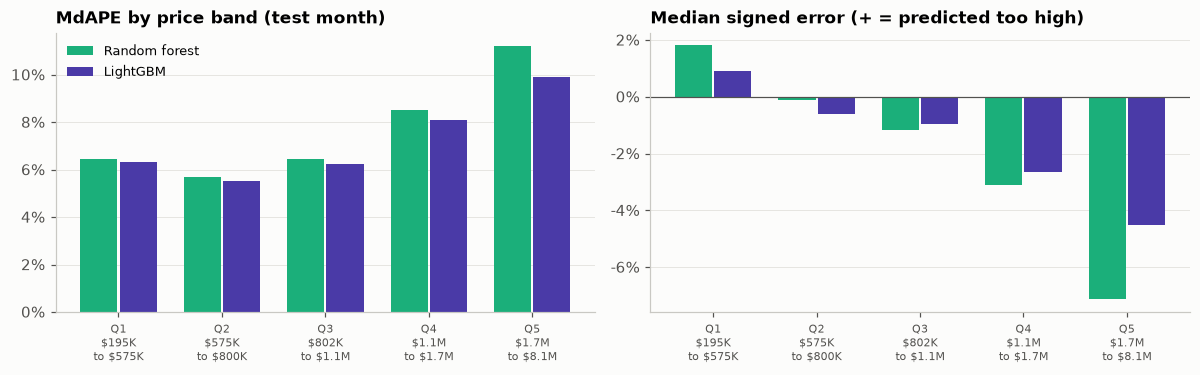

Highest test prediction: LightGBM $7.8M, random forest $7.0M; highest training price $8.3M


In [11]:
bands = pd.qcut(y_test, 5, labels=[f'Q{i}' for i in range(1, 6)])
edges = pd.Series(y_test).groupby(bands, observed=True).agg(['min', 'max'])
band = pd.DataFrame({'price range': [f'{money(a)} to {money(b)}' for a, b in edges.to_numpy()]}, index=edges.index)
for name in ['Random forest', 'LightGBM']:
    t = mdl.error_by_group(y_test, test_preds[name], bands)
    band[f'{name}: MdAPE'] = t['MdAPE']
    band[f'{name}: signed'] = t['median_signed_error']
display(band.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
x = np.arange(5)
ticks = [f'{q}\n' + r.replace('$', r'\$').replace(' to ', '\nto ') for q, r in zip(band.index, band['price range'])]
for k, name in enumerate(['Random forest', 'LightGBM']):
    axes[0].bar(x + (k - 0.5) * 0.38, band[f'{name}: MdAPE'], width=0.36, color=COLORS[name], label=name)
    axes[1].bar(x + (k - 0.5) * 0.38, band[f'{name}: signed'], width=0.36, color=COLORS[name], label=name)
for ax in axes:
    ax.set_xticks(x, ticks, fontsize=7.5)
    ax.grid(axis='x', visible=False)
axes[0].set_title('MdAPE by price band (test month)')
pct_axis(axes[0], 0)
axes[0].legend(frameon=False, fontsize=8.5)
axes[1].axhline(0, color='#52514e', lw=0.8)
axes[1].set_title('Median signed error (+ = predicted too high)')
pct_axis(axes[1], 0)
plt.tight_layout()
save_fig('06_error_by_band')
plt.show()

top = test_preds['LightGBM'].max()
print(f"Highest test prediction: LightGBM {money(top)}, random forest {money(test_preds['Random forest'].max())}; "
      f"highest training price {money(train_final[prep.TARGET].max())}")

**Month-level bias** (12-month window, from Section 5): the median signed error over all homes in a month, averaged in absolute size over the 13 months.

In [12]:
bias = stability.pivot(index='eval_month', columns='model', values='median_signed_error')[['Random forest', 'LightGBM']]
print('Average size of the monthly bias:', {m: f'{bias[m].abs().mean():.2f}%' for m in bias.columns})
bias.round(2)

Average size of the monthly bias: {'Random forest': '0.87%', 'LightGBM': '0.77%'}


model,Random forest,LightGBM
eval_month,,
2025-01,-0.65,-0.23
2025-02,-1.77,-2.26
2025-03,-1.80,-1.79
2025-04,-1.38,-1.18
2025-05,-0.77,-0.75
2025-06,-0.56,-0.24
2025-07,0.18,0.75
2025-08,0.78,0.26
2025-09,0.80,-0.20


## 8. What LightGBM relies on

LightGBM records how much each split reduced the training error (its *gain*). Summing the gain over all splits on a column, and adding up the columns that come from the same input (for example a value and its missing-value marker), shows which inputs the model leans on. The nearby-sales input is computed inside the pipeline but still appears as its own column.

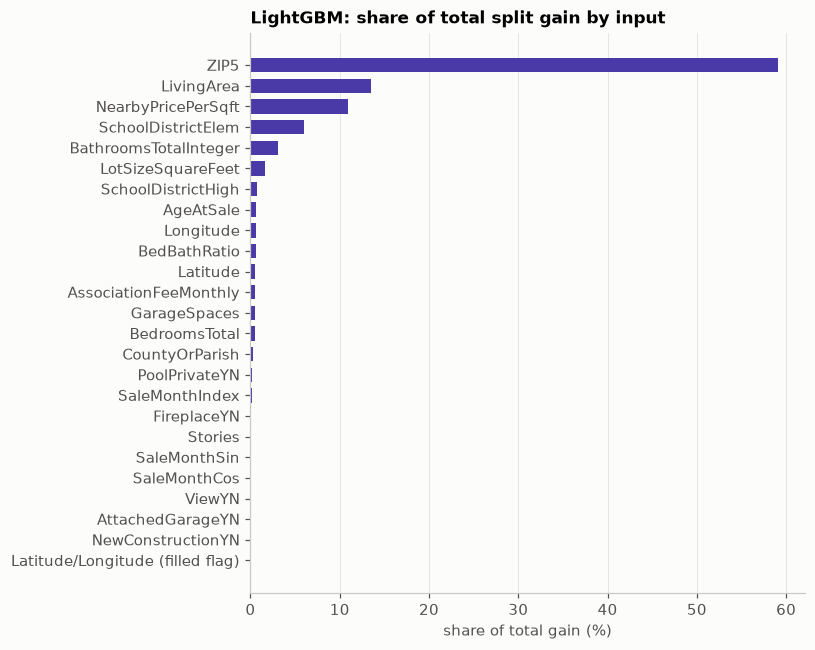

,share of gain (%)
ZIP5,59.10
LivingArea,13.50
NearbyPricePerSqft,10.90
SchoolDistrictElem,5.90
BathroomsTotalInteger,3.10
LotSizeSquareFeet,1.60
SchoolDistrictHigh,0.70
AgeAtSale,0.70


In [13]:
names = pre_final.get_feature_names_out()


def source_input(name):
    block, col = name.split('__', 1)
    col = col.replace('missingindicator_', '')
    if block == 'county':
        return 'CountyOrParish'
    if col == 'coords_imputed':
        return 'Latitude/Longitude (filled flag)'
    return col


gain = pd.Series(final_gb.booster_.feature_importance(importance_type='gain'), index=[source_input(n) for n in names])
gain = gain.groupby(level=0).sum()
gain = (100 * gain / gain.sum()).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.barh(gain.index, gain.values, color=COLORS['LightGBM'], height=0.7)
ax.set_xlabel('share of total gain (%)')
ax.set_title('LightGBM: share of total split gain by input')
ax.grid(axis='y', visible=False)
plt.tight_layout()
save_fig('06_gb_importance')
plt.show()
gain.sort_values(ascending=False).head(8).round(1).to_frame('share of gain (%)')

## 9. Saved results

Scores go to `results/` (no property data) and the chosen settings to `config/model_config_week7.json`.

In [14]:
gb_table.reset_index().assign(learning_rate=lambda d: [k[0] for k in d['setting']],
                              max_depth=lambda d: [k[1] for k in d['setting']],
                              n_estimators=lambda d: [k[2] for k in d['setting']]).drop(columns='setting').to_csv(
    RESULTS_DIR / '06_gb_tuning.csv', index=False, float_format='%.6f')
validation.reset_index(names='model').assign(eval_month=VALIDATION_MONTH, n_train_months=N_MONTHS).to_csv(
    RESULTS_DIR / '06_validation.csv', index=False, float_format='%.6f')
comparison.reset_index().assign(eval_month=TEST_MONTH).to_csv(RESULTS_DIR / '06_test_comparison.csv', index=False, float_format='%.6f')
stability.to_csv(RESULTS_DIR / '06_stability_2025.csv', index=False, float_format='%.6f')
window_effect.reset_index().to_csv(RESULTS_DIR / '06_window_effect.csv', index=False, float_format='%.6f')

config = {
    'random_seed': SEED,
    'inputs': FULL,
    'nearby_k': NEARBY_K,
    'n_train_months': N_MONTHS,
    'lightgbm': {**GB_SETTINGS, 'num_leaves': 2 ** GB_SETTINGS['max_depth'] - 1, 'min_child_samples': 20,
                 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'deterministic': True, 'n_jobs': 8},
    'random_forest': RF_SETTINGS,
    'selection_rule': 'one-standard-error rule, paired bootstrap over validation homes, fewest total leaves',
}
(ROOT / 'config' / 'model_config_week7.json').write_text(
    json.dumps(config, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o)))
print('Saved results and config/model_config_week7.json')

Saved results and config/model_config_week7.json


## 10. Summary and next steps

**Test month (April 2026), new inputs, 24 training months:**

| Model | R² | MAPE | MdAPE | MAE | Homes within 10% |
|---|---:|---:|---:|---:|---:|
| Linear regression | 0.867 | 13.10% | 9.46% | $175,061 | 52.0% |
| Random forest (Week 6) | 0.900 | 10.81% | 7.40% | $148,862 | 61.4% |
| **LightGBM** | **0.920** | **10.12%** | **7.00%** | **$136,276** | **64.2%** |

For reference, the Week 4 baseline scored MdAPE 11.38% (R² 0.820) and the Week 5 random forest 7.76% (R² 0.885).

**Chosen settings.** Learning rate 0.05, depth 8 (at most 255 leaves per tree), 3,000 trees, validation MdAPE 6.96%. No simpler setting was within one standard error of it. This setting lies at the edge of the grid (the deepest trees and the most trees tried), so slightly larger models might do a little better; at learning rate 0.1 the curves flatten after about 2,000 trees, which suggests the remaining gain is small.

**The gain over the random forest is real.**
- Test month: 0.41 MdAPE points better, 95% range 0.27 to 0.58.
- All 13 months checked (12-month window): better every month, by 0.20 to 0.47 points (mean 0.35).

**Where it helps most: expensive homes.** For the most expensive fifth (Q5), MdAPE falls from 11.22% (forest) to 9.91%, and the typical underpricing from −7.1% to −4.5%. Its highest test prediction is $7.8M against the forest's $7.0M (highest training price $8.3M), so it is pulled toward the middle less. The cheaper bands improve by 0.1 to 0.5 points. The average size of the month-level bias falls from 0.87% to 0.77%.

**What it relies on.** Share of total split gain: ZIP code 59%, living area 14%, nearby-sales price per square foot 11%, elementary school district 6%. Gain shares favor inputs with many distinct values, so they show what the model uses, not what each input is worth on its own.

**Week 6's open question: why the 24-month window helps.** On the same 27,484 validation homes (January to March 2026), the forest gains from 24 instead of 12 months with the original inputs (0.24 points, range 0.17 to 0.33) as well as with the new inputs (0.16 points, range 0.08 to 0.24). The gain therefore comes mainly from more training data, not from the new inputs making older sales usable, which corrects the explanation offered in Week 6. Week 3 chose 12 months using a linear regression and a quick boosted model on the original inputs; for the forest, more data helps regardless.

**Next steps (Week 8, evaluation)**
1. Report MAPE and MdAPE by price band and by county for the final model, and save the summary as `metrics_summary.csv`, as the Week 8 task asks.
2. Use LightGBM with the new inputs and 24 months as the final model.
3. Optionally extend the LightGBM grid one step (more trees, depth 9) to confirm the edge-of-grid choice.